# 11.11日学习笔记
## 1.exercise
### 1.1 linear-regression-concise
1.1.1如果将小批量的总损失替换为小批量损失的平均值，需要如何更改学习率？

 answer：

 这个时候损失函数loss会变成原来的$\frac{1}{n}$倍，那么梯度也会变成原来的$\frac{1}{n}$倍，因此学习率应该变成原来的$n$倍就可以达到相同的效果。

1.1.2 查看深度学习框架文档，他们提供了哪些损失函数和初始化方法？用Huber损失代替原损失，即$$l(y,\hat{y})=\begin{cases}|y-\hat{y}|-\frac{\sigma}{2} ,if \ |y-\hat{y}|\gt \sigma\\ \\\frac{1}{2\sigma}(y-\hat{y})^{2}\end{cases}$$
 
 answer:

 常见损失函数：  
 nn.L1Loss  
 nn.MSELoss  
 nn.CrossEntropyLoss  
 nn.LinearCrossEntropyOptions  

 常见初始化方法：  
 zeros_()   
 ones_()     
 constant_()   
 normal_()  

 Huber损失：  
 介于L2损失和L1损失之间的一种损失函数：
 给定一个误差$\sigma$,当现在的误差非常大的时候使用绝对值误差；当现在的误差比较小的时候使用平方误差。  
 如果我们想要拟合的函数是$y=\omega x+b$求导后可以看到：  
 $$\frac{\partial L}{\partial \omega}=\frac{\partial L}{\partial \hat{y}}\frac{\partial\hat{y}}{\partial\omega}=L^{\prime}(\hat{y})x$$
 因此损失函数对$\omega$的梯度就是：
 $$J(\omega,b)=\frac{1}{n}\sum_{i=1}^{n}L^{\prime}(\hat{y_{i}})x_{i}$$
 因此Huber有这样的特性：  
 对于误差特别大的地方梯度不会随着误差变大而变大，换言之对误差大的地方不敏感，参数调整不会特别大；  
 反而对于误差比较小的地方梯度会随着误差变小而变小，因此会更加光滑，可以避免震荡的情形出现

1.1.3 如何访问线性回归的梯度？
 
answer:

w.grad()
b.grad()





## 2.softmax-regression
### 2.1 classification_problem
独热编码(one-hot-encoding):对于$n$个类的分类问题，使用$$\{(1,0,...,0),(0,1,0,...)\}$$
### 2.2 softmax function
我们预测的结果实际上是一个n维的向量$$\hat{\mathbf{y}}\in\mathbb{R}^{n}$,其中我们希望第$i$个分量是对应第$i$类的概率。  
处于概率学的考量，我们自然希望每个分量是非负的并且加起来等于1
$$\hat{\mathbf{y}}=softmax(\mathbf{o}),\hat{\mathbf{y_{i}}}=\frac{exp(o_{j})}{\sum_{k}exp(o_{k})}$$
### 2.3 对数似然
假设整个数据集是$\{\mathbf{X},\mathbf{Y}\}$,其中第$i$个样本记为$(\mathbf{x}^{i},y^{i})$
那么可以有
$$P(\mathbf{Y}|\mathbf{X})=\prod_{i=1}^{n}P(y^{i}|\mathbf{x}^{i})$$
根据最大似然估计，最大化LHS等价于最小化负对数似然，对于标签$y$和模型预测$\hat{y}$,损失函数为：
$$l(y,\hat{y})=-\sum_{j=1}^{q}y_{j}log \hat{y_{j}}$$
带入
$$\hat{\mathbf{y}}=softmax(\mathbf{o}),\hat{\mathbf{y_{i}}}=\frac{exp(o_{j})}{\sum_{k}exp(o_{k})}$$
得到
$$\begin{align}
l(\mathbf{y},\hat{\mathbf{y}})&= -\sum_{j=1}^{q}y_{j}log \frac{exp(o_{j})}{\sum_{k=1}^{q}exp(o_{k})}
\\ 
&=\sum_{j=1}^{q}y_{j}log\sum_{k=1}^{q}\exp(o_{k})-\sum_{j=1}^{q}y_{j}o_{j} \\ 
&=log\sum_{k=1}^{q}\exp(o_{k})-\sum_{j=1}^{q}y_{j}o_{j}
\end{align}$$
那么$$\partial_{o_{j}}l(\mathbf{y},\hat{\mathbf{y}})=softmax(\mathbf{o}_{j})-y_{j}$$

### information theory:
熵(entropy):
对于一个给定的离散分布$P$,它的熵定义为
$$H[P] = \sum_{j}-P(j)log P(j)$$
如果我们不能完全预测每一个时间，那么我们有时可能会感到惊异，这个惊异程度可以倍信息量$-log P(j)$来刻画，当这个事件被赋予的主观概率很低的时候，这个时间的信息量就会很大
交叉熵(cross entropy):
$H(P,Q)$可以被认为是“主观概率为Q的观察者在看到根据概率P生成的数据时的预期惊异”

### exercise:
1.我们可以更深入地探讨指数族与softmax之间的联系。
    A.计算softmax交叉熵损失$l(\mathbf{y},\hat{\mathbf{y}})$的二阶导数
    B.计算softmax($\mathbf{o}$)给出的分布方差，并与上面的计算匹配
answer:

$$\frac{\partial l}{\partial o_{i}}= p_{i}-y_{i}$$
那么二阶导数实际上就是：
$$\frac{\partial^{2}l}{\partial o_{i}\partial o_{j}}=\frac{\partial p_{i}}{\partial o_{j}}=(\delta_{ij}-p_{j})p_{i}$$
那么交叉熵的Hessian就是
$$\mathbf{H}=diag{\mathbf{p}}-\mathbf{p}\mathbf{p}^{T}$$
$$\nabla_{\mathbf{o}}^{2}l=Cov(X)$$

2.假设我们有三个类发生的概率相等，即概率向量是$(\frac{1}{3}),\frac{1}{3}),\frac{1}{3})$
 A.如果我们尝试为它设计二进制代码，有什么问题？ 
 
 answer：

 如果是二进制代码，1bit是不够的，通过计算它的信息熵得到约等于1.585，因此至少需要两个bit

B.请设计一个更好的代码。提示：如果我们尝试编码两个独立的观察结果会发生什么？如果我们联合编码n个观测值怎么办？

answer：

此时的信息熵是$nlog_{2}3$  
根据Shannon源编码原理，可以找到前缀编码，使得总平均编码长度$L_{n}$满足：
$$log_{2}3\le \frac{L_{n}}{n}\lt log_{2}3+\frac{1}{n}$$
令n趋于正无穷，那么平均编码长度趋于信息熵（当然是单调递减趋于信息熵）

3.softmax是对上面介绍的映射的误称。真正的softmax定义为RealSoftMax(a,b)=log(exp(a)+exp(b))
A.证明RealSoftMax(a,b)>max(a,b)

answer:

显然

B.证明$\lambda^{-1}RealSoftMax(\lambda a,\lambda b)>max(a,b)$

answer:

均值不等式

C.证明$\lambda \rightarrow +\infty$时收敛到max

answer：

分离最大值即可

D.softmin会是什么样子

answer：

SoftMin(a,b)= -ln(\exp(-a)+\exp(-b))即可

E.推广到n个数呢？

answer：

$$SoftMax(\mathbf{a})=log(\sum_{i=1}^{n}\exp a_{i})$$



## 3. softmax outline 
(including image-classification-dataset & softmax-regression & softmax-regression-concise)
### 3.1 准备数据集

训练集的大小是： 60000
测试集的大小是： 10000
单个数据的形状是： torch.Size([1, 28, 28])


array([<AxesSubplot:title={'center':'ankle boot'}>,
       <AxesSubplot:title={'center':'t-shirt'}>,
       <AxesSubplot:title={'center':'t-shirt'}>,
       <AxesSubplot:title={'center':'dress'}>,
       <AxesSubplot:title={'center':'t-shirt'}>,
       <AxesSubplot:title={'center':'pullover'}>,
       <AxesSubplot:title={'center':'sneaker'}>,
       <AxesSubplot:title={'center':'pullover'}>,
       <AxesSubplot:title={'center':'sandal'}>,
       <AxesSubplot:title={'center':'sandal'}>,
       <AxesSubplot:title={'center':'t-shirt'}>,
       <AxesSubplot:title={'center':'ankle boot'}>,
       <AxesSubplot:title={'center':'sandal'}>,
       <AxesSubplot:title={'center':'sandal'}>,
       <AxesSubplot:title={'center':'sneaker'}>,
       <AxesSubplot:title={'center':'ankle boot'}>,
       <AxesSubplot:title={'center':'trouser'}>,
       <AxesSubplot:title={'center':'t-shirt'}>], dtype=object)

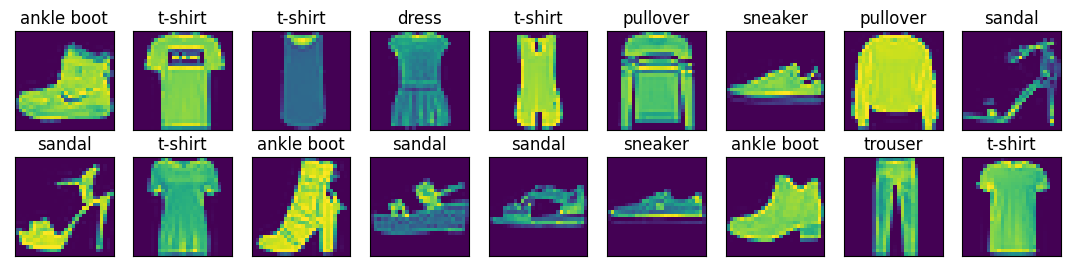

In [5]:
# 导入要用到的库
%matplotlib inline
import torch
import torchvision
from torch.utils import data
from torchvision import transforms
from d2l import torch as d2l
# 把Fashion-MNIST数据集下载并读取到内存中
trans = transforms.ToTensor()
mnist_train = torchvision.datasets.FashionMNIST(
    root="D:\机器学习\ML_30_Days\data", train=True,
     transform=trans, download=True)
mnist_test = torchvision.datasets.FashionMNIST(
    root="D:\机器学习\ML_30_Days\data", train=False,
     transform=trans, download=True)
# 展示数据集和训练集的大小
print("训练集的大小是：",len(mnist_train))
print("测试集的大小是：",len(mnist_test))
# 展示一份数据（一个图像的灰度图）
print("单个数据的形状是：", mnist_train[0][0].shape)
# 定义一个函数，把类别编号映射到类别名称
def get_fashion_mnist_labels(labels): 
    text_labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
                   'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
    return [text_labels[int(i)] for i in labels]
# 定义一个函数，把单个数据可以画出来
def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize )
    axes = axes.flatten()
    for i, (ax, img) in enumerate(zip(axes, imgs)):
        if torch.is_tensor(img):
            ax.imshow(img.numpy())
        else:
            ax.imshow(img)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        if titles:
            ax.set_title(titles[i])
    return axes
# 举个例子
X, y = next(iter(data.DataLoader(mnist_train, batch_size=18)))
show_images(X.reshape(18, 28, 28), 2, 9, titles=get_fashion_mnist_labels(y))

In [8]:
# 读取小批量的数据
batch_size = 256
def get_dataloader_workers():
    return 4
train_iter = data.DataLoader(mnist_train, batch_size, shuffle=True,
                              num_workers=get_dataloader_workers())
timer = d2l.Timer()
for X,y in train_iter:
    continue
f'{timer.stop():.2f}sec'
# 整合所有组件：
# 1.返回训练集和验证集的数据迭代器
# 2.可以讲图像大小调整为另一种形状
def load_data_fashion_mnist(batch_size, resize=None):
    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    mnist_train = torchvision.datasets.FashionMNIST(
        root="D:\机器学习\ML_30_Days\data", train=True,
        transform=trans, download=True)
    mnist_test = torchvision.datasets.FashionMNIST(
        root="D:\机器学习\ML_30_Days\data", train=False,
        transform=trans, download=True)
    return(data.DataLoader(mnist_train, batch_size, shuffle=True, 
                           num_workers=get_dataloader_workers()),
            data.DataLoader(mnist_test, batch_size, shuffle=False, 
                           num_workers=get_dataloader_workers()))
# 一次测试
train_iter, test_iter = load_data_fashion_mnist(32, resize=64)
for X, y in train_iter:
    print(X.shape, X.dtype, y.shape, y.dtype)
    break

torch.Size([32, 1, 64, 64]) torch.float32 torch.Size([32]) torch.int64
